# Task 4 — Third Model, Full Comparison and Error Analysis

1. **Third model:** **EfficientNet-B0** (Task 1 memo, section 8), trained with the same frozen-base protocol as Task 2.
2. **Bonus:** fine-tuning of MobileNetV3-Small (last 3 blocks unfrozen, learning rate lowered 10×), with the delta reported against the frozen baseline.
3. **Full comparison** of all models on the same 270 test images: accuracy, precision, recall, F1, latency, size, parameters, training time.
4. **Visualisations:** accuracy-vs-speed chart and confusion matrices side by side.
5. **Error analysis:** recall per defect for every model, the hardest defect, and a failure gallery.

The decision memo built on these results is [`DECISION_MEMO.md`](DECISION_MEMO.md).

| | |
|---|---|
| Split | `common/split_70_15_15.jsonl`: 1260 / 270 / 270, the same for every model |
| Seed | **24500003** (student ID) |
| Hardware | i7-10750H, CPU |
| Positive class | **bad**, threshold 0.5 (not tuned) |

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

PRACTICE = Path.cwd().parent
sys.path.insert(0, str(PRACTICE / "common"))
import quality_common as qc
import torch_models as tm

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
DEVICE = "cpu"

HP_FROZEN = dict(tm.DEFAULT_HP)                                    # identical to Task 2
HP_FINETUNE = dict(tm.DEFAULT_HP, learning_rate=1e-4, max_epochs=15, trainable_blocks=3)
print("frozen protocol   :", HP_FROZEN)
print("fine-tune protocol:", HP_FINETUNE)

frozen protocol   : {'seed': 24500003, 'image_size': 224, 'batch_size': 32, 'learning_rate': 0.001, 'max_epochs': 30, 'patience': 5, 'hidden_units': 128, 'dropout': 0.3, 'threshold': 0.5}
fine-tune protocol: {'seed': 24500003, 'image_size': 224, 'batch_size': 32, 'learning_rate': 0.0001, 'max_epochs': 15, 'patience': 5, 'hidden_units': 128, 'dropout': 0.3, 'threshold': 0.5, 'trainable_blocks': 3}


## 1. Data (same split and preprocessing as Task 2)

EfficientNet-B0's native input is **224×224 with ImageNet mean/std**, the same as the MobileNets, so the family-appropriate preprocessing is identical.

The torchvision reference pipeline would also resize to 256 and center-crop 224. That crop is **not** used: it would cut 12 % off the page borders, where occlusion blocks, glare spots and skew corners often are. Every model sees the full document.

In [2]:
splits = qc.load_split()
qc.check_split(splits)
data = {s: qc.load_images(splits[s], size=224) for s in qc.SPLITS}
x_te, y_te = data["test"]
test_records = splits["test"]

train       1260 (70%)  good=630 bad=630  inn=420 passport=420 snils=420
validation   270 (15%)  good=135 bad=135  inn=90 passport=90 snils=90
test         270 (15%)  good=135 bad=135  inn=90 passport=90 snils=90
No source_id appears in two splits: OK


## 2. Third model: EfficientNet-B0 (frozen base, Task 2 protocol)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Vlad/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


0.6%

1.2%

1.8%

2.4%

3.1%

... (173 outputs left out)

[efficientnet_b0] epoch 14  train loss 0.0891 acc 0.974 | val loss 0.0566 acc 0.985


[efficientnet_b0] epoch 15  train loss 0.0951 acc 0.966 | val loss 0.0787 acc 0.967


[efficientnet_b0] epoch 16  train loss 0.0884 acc 0.969 | val loss 0.0655 acc 0.985


[efficientnet_b0] epoch 17  train loss 0.0955 acc 0.966 | val loss 0.0571 acc 0.981
early stopping: no val_loss improvement for 5 epochs
best epoch 12, training time 627 s


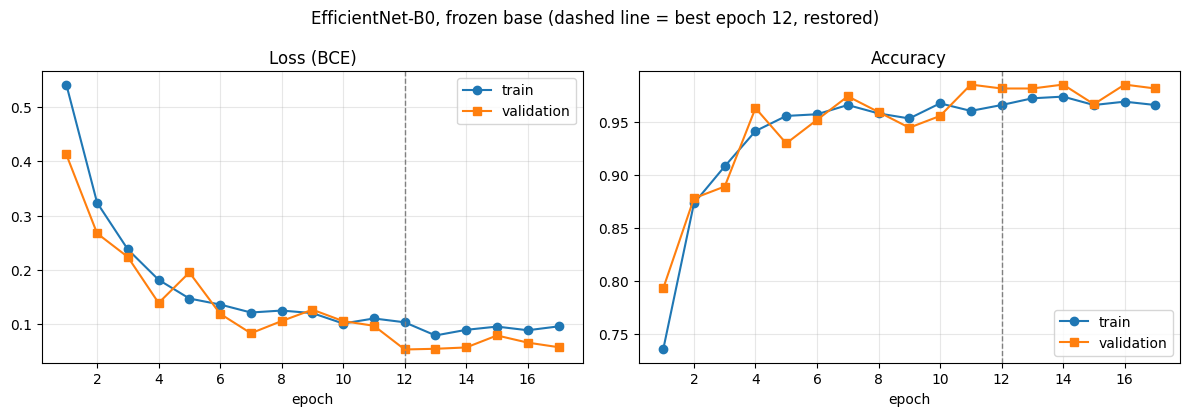

In [3]:
qc.set_seed(HP_FROZEN["seed"])
effnet = tm.QualityNet("efficientnet_b0")
total, trainable = tm.count_params(effnet)
print(f"EfficientNet-B0: total {total:,}  trainable {trainable:,}")
effnet, eff_hist, eff_time, eff_best = tm.train_model(effnet, data, HP_FROZEN, DEVICE, tag="efficientnet_b0")
torch.save(effnet.state_dict(), OUT / "efficientnet_b0_frozen.pt")
pd.DataFrame(eff_hist).to_csv(OUT / "efficientnet_b0_history.csv", index=False)
qc.plot_history(eff_hist, "EfficientNet-B0, frozen base", OUT / "efficientnet_b0_curves.png"); plt.show()

## 3. Bonus: fine-tuning MobileNetV3-Small with a lowered learning rate

- **Start:** the Task 2 frozen checkpoint.
- **Unfrozen:** the last 3 backbone blocks; BatchNorm statistics stay frozen.
- **Optimizer:** Adam with lr **1e-4**, 10× lower than for the head, so the pretrained features are adapted rather than destroyed.
- Same augmentation and early stopping as before.

MobileNetV3-Small fine-tune: trainable 718,625 of 1,000,993 (72%)


[mobilenet_v3_small_ft] epoch  1  train loss 0.0928 acc 0.964 | val loss 0.0535 acc 0.993


[mobilenet_v3_small_ft] epoch  2  train loss 0.0564 acc 0.983 | val loss 0.0403 acc 0.981


[mobilenet_v3_small_ft] epoch  3  train loss 0.0602 acc 0.980 | val loss 0.0414 acc 0.985


[mobilenet_v3_small_ft] epoch  4  train loss 0.0490 acc 0.985 | val loss 0.0221 acc 0.993


[mobilenet_v3_small_ft] epoch  5  train loss 0.0371 acc 0.990 | val loss 0.0288 acc 0.993


... (6 outputs left out)

[mobilenet_v3_small_ft] epoch 12  train loss 0.0238 acc 0.992 | val loss 0.0126 acc 1.000


[mobilenet_v3_small_ft] epoch 13  train loss 0.0172 acc 0.995 | val loss 0.0101 acc 0.996


[mobilenet_v3_small_ft] epoch 14  train loss 0.0215 acc 0.993 | val loss 0.0093 acc 0.996


[mobilenet_v3_small_ft] epoch 15  train loss 0.0270 acc 0.990 | val loss 0.0114 acc 1.000
best epoch 14, training time 148 s


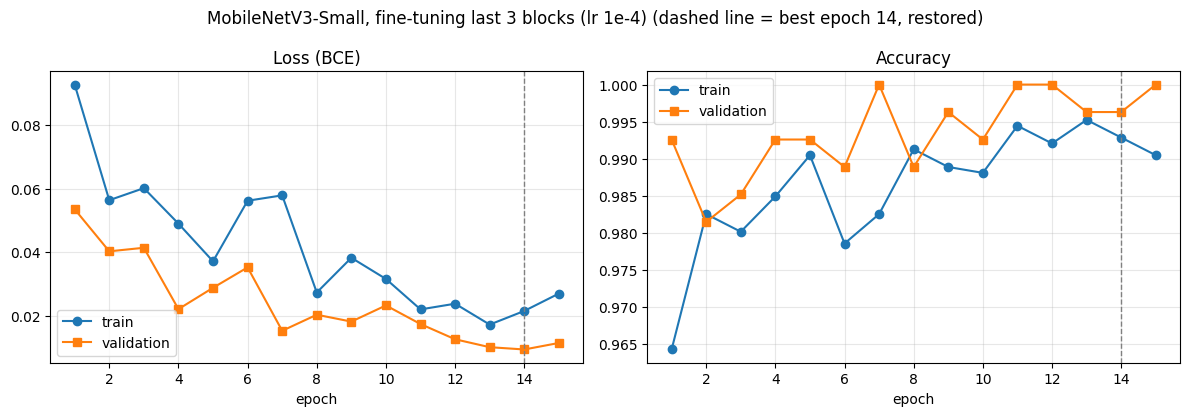

In [4]:
qc.set_seed(HP_FINETUNE["seed"])
v3_ft = tm.QualityNet("mobilenet_v3_small")
v3_ft.load_state_dict(torch.load(PRACTICE / "task2" / "outputs" / "mobilenet_v3_small_frozen.pt"))
v3_ft.freeze_backbone(trainable_blocks=HP_FINETUNE["trainable_blocks"])
total, trainable = tm.count_params(v3_ft)
print(f"MobileNetV3-Small fine-tune: trainable {trainable:,} of {total:,} ({trainable/total:.0%})")
v3_ft, ft_hist, ft_time, ft_best = tm.train_model(v3_ft, data, HP_FINETUNE, DEVICE, tag="mobilenet_v3_small_ft")
torch.save(v3_ft.state_dict(), OUT / "mobilenet_v3_small_finetuned.pt")
pd.DataFrame(ft_hist).to_csv(OUT / "mobilenet_v3_small_finetuned_history.csv", index=False)
qc.plot_history(ft_hist, "MobileNetV3-Small, fine-tuning last 3 blocks (lr 1e-4)", OUT / "mobilenet_v3_small_finetuned_curves.png"); plt.show()

## 4. Test predictions of all models

- **Task 2 models:** reloaded from their saved weights, then predicted again (this reproduces the Task 2 numbers exactly).
- **YOLO models:** predictions are read from the Task 3 output.
- **New models:** predicted here.

Latency is **re-measured for every model in this same session** with the same protocol (batch 1, 224×224, fp32, 10 warm-up + mean of 100 runs). Small differences from earlier tasks are normal run-to-run variation; this table is the consistent one.

In [5]:
from ultralytics import YOLO

t2 = json.loads((PRACTICE / "task2" / "outputs" / "test_metrics.json").read_text())["results"]
t3 = json.loads((PRACTICE / "task3" / "outputs" / "test_metrics.json").read_text())["results"]

def load_task2(arch):
    m = tm.QualityNet(arch)
    m.load_state_dict(torch.load(PRACTICE / "task2" / "outputs" / f"{arch}_frozen.pt"))
    return m.eval()

MODELS = {
    # name: (display, nn.Module for latency, prob_bad on test, train_time_s, regime)
    "mobilenet_v3_small": ("MobileNetV3-Small", load_task2("mobilenet_v3_small"), None, t2["mobilenet_v3_small"]["train_time_s"], "frozen"),
    "mobilenet_v2":       ("MobileNetV2", load_task2("mobilenet_v2"), None, t2["mobilenet_v2"]["train_time_s"], "frozen"),
    "yolov8n_cls":        ("YOLOv8n-cls", YOLO(PRACTICE / "task3" / "runs" / "yolov8n_cls" / "weights" / "best.pt").model.float().eval(),
                           None, t3["yolov8n_cls"]["train_time_s"], "full fine-tune"),
    "yolov8s_cls":        ("YOLOv8s-cls", YOLO(PRACTICE / "task3" / "runs" / "yolov8s_cls" / "weights" / "best.pt").model.float().eval(),
                           None, t3["yolov8s_cls"]["train_time_s"], "full fine-tune"),
    "efficientnet_b0":    ("EfficientNet-B0", effnet.eval(), None, eff_time, "frozen"),
    "mobilenet_v3_small_ft": ("MobileNetV3-Small FT (bonus)", v3_ft.eval(), None, t2["mobilenet_v3_small"]["train_time_s"] + ft_time,
                              "frozen + fine-tune last 3 blocks"),
}

probs = {}
for name, (disp, net, _, _, _) in MODELS.items():
    if name.startswith("yolo"):
        pred = pd.read_csv(PRACTICE / "task3" / "outputs" / f"{name}_test_predictions.csv").set_index("image_id")
        probs[name] = pred.loc[[r["image_id"] for r in test_records], "prob_bad"].to_numpy()
    else:
        probs[name] = tm.predict(net, x_te)
pd.DataFrame({"image_id": [r["image_id"] for r in test_records], **probs}).to_csv(OUT / "all_test_predictions.csv", index=False)
print("predictions:", {k: v.shape for k, v in probs.items()})

predictions: {'mobilenet_v3_small': (270,), 'mobilenet_v2': (270,), 'yolov8n_cls': (270,), 'yolov8s_cls': (270,), 'efficientnet_b0': (270,), 'mobilenet_v3_small_ft': (270,)}


## 5. Full comparison table

In [6]:
rows, report = [], {}
for name, (disp, net, _, train_time, regime) in MODELS.items():
    m = qc.compute_metrics(y_te.numpy(), probs[name])
    parts = qc.breakdown(test_records, probs[name])
    lat, lat_std = qc.cpu_latency_ms(net)
    size = qc.model_size_mb(net)
    params = sum(p.numel() for p in net.parameters())
    checks = qc.acceptance_check(m, parts, lat, size)
    report[name] = {"display": disp, "regime": regime, "metrics": m, "breakdown": parts,
                    "cpu_latency_ms": [round(lat, 1), round(lat_std, 1)], "size_mb_fp32": round(size, 1),
                    "params_total": params, "train_time_s": round(train_time, 1), "acceptance": checks,
                    "passes_all": all(checks.values())}
    rows.append({"model": disp, "regime": regime, "accuracy": m["accuracy"], "precision_bad": m["precision_bad"],
                 "recall_bad": m["recall_bad"], "f1_bad": m["f1_bad"],
                 "FN": m["confusion_matrix"][1][0], "FP": m["confusion_matrix"][0][1],
                 "cpu_latency_ms": round(lat, 1), "size_mb": round(size, 1), "params_M": round(params / 1e6, 2),
                 "train_time_min": round(train_time / 60, 1), "passes_criteria": all(checks.values())})
table = pd.DataFrame(rows).set_index("model")
table.to_csv(OUT / "comparison_table.csv")
table.round(4)

,regime,accuracy,precision_bad,recall_bad,f1_bad,FN,FP,cpu_latency_ms,size_mb,params_M,train_time_min,passes_criteria
model,,,,,,,,,,,,
MobileNetV3-Small,frozen,0.9778,0.9924,0.9630,0.9774,5,1,10.4,3.9,1.00,3.4,True
MobileNetV2,frozen,0.9852,0.9852,0.9852,0.9852,2,2,20.7,9.3,2.39,16.4,True
YOLOv8n-cls,full fine-tune,0.9963,1.0000,0.9926,0.9963,1,0,9.5,5.6,1.44,5.8,True
YOLOv8s-cls,full fine-tune,1.0000,1.0000,1.0000,1.0000,0,0,18.5,19.5,5.08,17.2,True
EfficientNet-B0,frozen,0.9926,1.0000,0.9852,0.9925,2,0,31.0,16.2,4.17,10.4,True
MobileNetV3-Small FT (bonus),frozen + fine-tune last 3 blocks,0.9963,1.0000,0.9926,0.9963,1,0,10.7,3.9,1.00,5.9,True


## 6. Visualisations

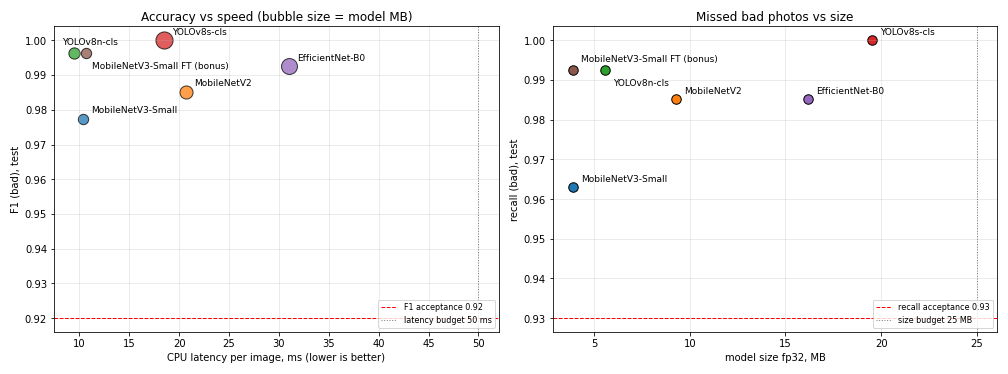

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
colors = plt.cm.tab10(np.arange(len(report)))
# label offsets (points) so that labels of models with almost equal values do not overlap
OFFSETS = {"YOLOv8n-cls": (-12, 9), "MobileNetV3-Small FT (bonus)": (6, -15), "MobileNetV3-Small": (8, 6),
           "MobileNetV2": (8, 6), "YOLOv8s-cls": (8, 6), "EfficientNet-B0": (8, 6)}
OFFSETS_R = {"YOLOv8n-cls": (8, -16), "MobileNetV3-Small FT (bonus)": (8, 8)}
for (name, rep), c in zip(report.items(), colors):
    lat, f1, size = rep["cpu_latency_ms"][0], rep["metrics"]["f1_bad"], rep["size_mb_fp32"]
    disp = rep["display"]
    axes[0].scatter(lat, f1, s=60 + size * 12, color=c, alpha=.75, edgecolor="k")
    axes[0].annotate(disp, (lat, f1), textcoords="offset points", xytext=OFFSETS.get(disp, (8, 6)), fontsize=9)
    axes[1].scatter(size, rep["metrics"]["recall_bad"], s=90, color=c, edgecolor="k")
    axes[1].annotate(disp, (size, rep["metrics"]["recall_bad"]), textcoords="offset points",
                     xytext=OFFSETS_R.get(disp, (8, 6)), fontsize=9)
axes[0].axhline(0.92, color="red", ls="--", lw=1, label="F1 acceptance 0.92")
axes[0].axvline(50, color="gray", ls=":", lw=1, label="latency budget 50 ms")
axes[0].set_xlabel("CPU latency per image, ms (lower is better)"); axes[0].set_ylabel("F1 (bad), test")
axes[0].set_title("Accuracy vs speed (bubble size = model MB)")
axes[1].axhline(0.93, color="red", ls="--", lw=1, label="recall acceptance 0.93")
axes[1].axvline(25, color="gray", ls=":", lw=1, label="size budget 25 MB")
axes[1].set_xlabel("model size fp32, MB"); axes[1].set_ylabel("recall (bad), test")
axes[1].set_title("Missed bad photos vs size")
for ax in axes: ax.grid(alpha=.3); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); fig.savefig(OUT / "accuracy_vs_speed.png", dpi=130); plt.show()

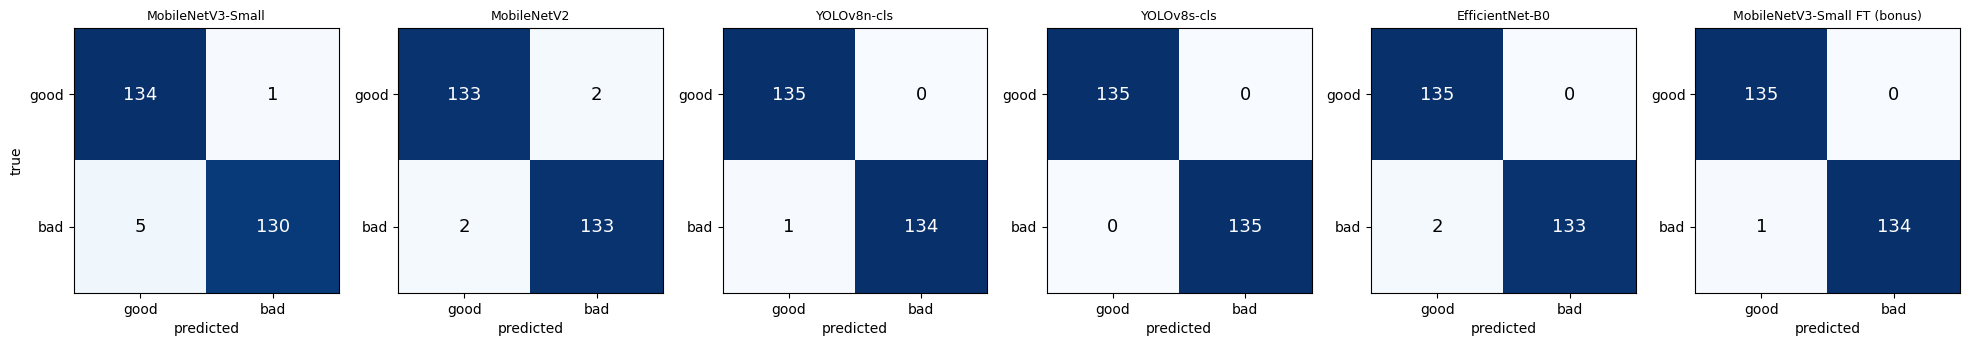

In [8]:
n = len(report)
fig, axes = plt.subplots(1, n, figsize=(3.3 * n, 3.6))
for ax, (name, rep) in zip(axes, report.items()):
    cm = np.array(rep["metrics"]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=135)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > 70 else "black")
    ax.set_xticks([0, 1], ["good", "bad"]); ax.set_yticks([0, 1], ["good", "bad"])
    ax.set_xlabel("predicted"); ax.set_title(rep["display"], fontsize=9)
axes[0].set_ylabel("true")
plt.tight_layout(); fig.savefig(OUT / "confusion_matrices.png", dpi=130); plt.show()

## 7. Error analysis

### 7.1 Recall per defect type (bad images) and accuracy on good images per augmentation

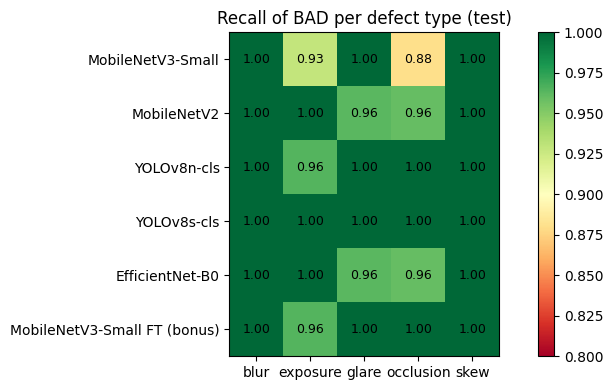

Mean recall per defect over all models (hardest first):
occlusion    0.9667
exposure     0.9762
glare        0.9877
blur         1.0000
skew         1.0000

Missed bad images per defect, summed over all models:
occlusion    5
exposure     4
glare        2
blur         0
skew         0

Accuracy on GOOD images per augmentation:
                              none  rotate_270  rotate_90  slight_rotation  upside_down
MobileNetV3-Small              1.0       0.929        1.0            1.000          1.0
MobileNetV2                    1.0       1.000        1.0            0.951          1.0
YOLOv8n-cls                    1.0       1.000        1.0            1.000          1.0
YOLOv8s-cls                    1.0       1.000        1.0            1.000          1.0
EfficientNet-B0                1.0       1.000        1.0            1.000          1.0
MobileNetV3-Small FT (bonus)   1.0       1.000        1.0            1.000          1.0


In [9]:
defects = pd.DataFrame({rep["display"]: rep["breakdown"]["recall_bad_per_defect"] for rep in report.values()}).T
augs = pd.DataFrame({rep["display"]: rep["breakdown"]["accuracy_good_per_augmentation"] for rep in report.values()}).T
defects["mean"] = defects.mean(axis=1)
mean_per_defect = defects.drop(columns="mean").mean(axis=0).sort_values()
errors_per_defect = pd.Series({d: sum(int(((probs[n] < .5) & np.array([r["quality_label"] == "bad" and r["defect_type"] == d
                                                                    for r in test_records])).sum()) for n in report)
                               for d in mean_per_defect.index}).sort_values(ascending=False)
defects.to_csv(OUT / "recall_per_defect.csv"); augs.to_csv(OUT / "accuracy_good_per_augmentation.csv")

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(defects.drop(columns="mean").values, cmap="RdYlGn", vmin=0.8, vmax=1.0)
ax.set_xticks(range(len(defects.columns) - 1), defects.columns[:-1]); ax.set_yticks(range(len(defects)), defects.index)
for i in range(len(defects)):
    for j in range(len(defects.columns) - 1):
        ax.text(j, i, f"{defects.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Recall of BAD per defect type (test)"); plt.colorbar(im, ax=ax)
plt.tight_layout(); fig.savefig(OUT / "recall_per_defect.png", dpi=130); plt.show()

print("Mean recall per defect over all models (hardest first):"); print(mean_per_defect.round(4).to_string())
print("\nMissed bad images per defect, summed over all models:"); print(errors_per_defect.to_string())
print("\nAccuracy on GOOD images per augmentation:"); print(augs.round(3).to_string())

### 7.2 Failure gallery: test images misclassified by at least one model

11 of 270 test images are misclassified by at least one model
true  defect/augmentation 
bad   exposure                3
      glare                   2
      occlusion               3
good  rotate_270              1
      slight_rotation_-5.7    1
      slight_rotation_3.4     1


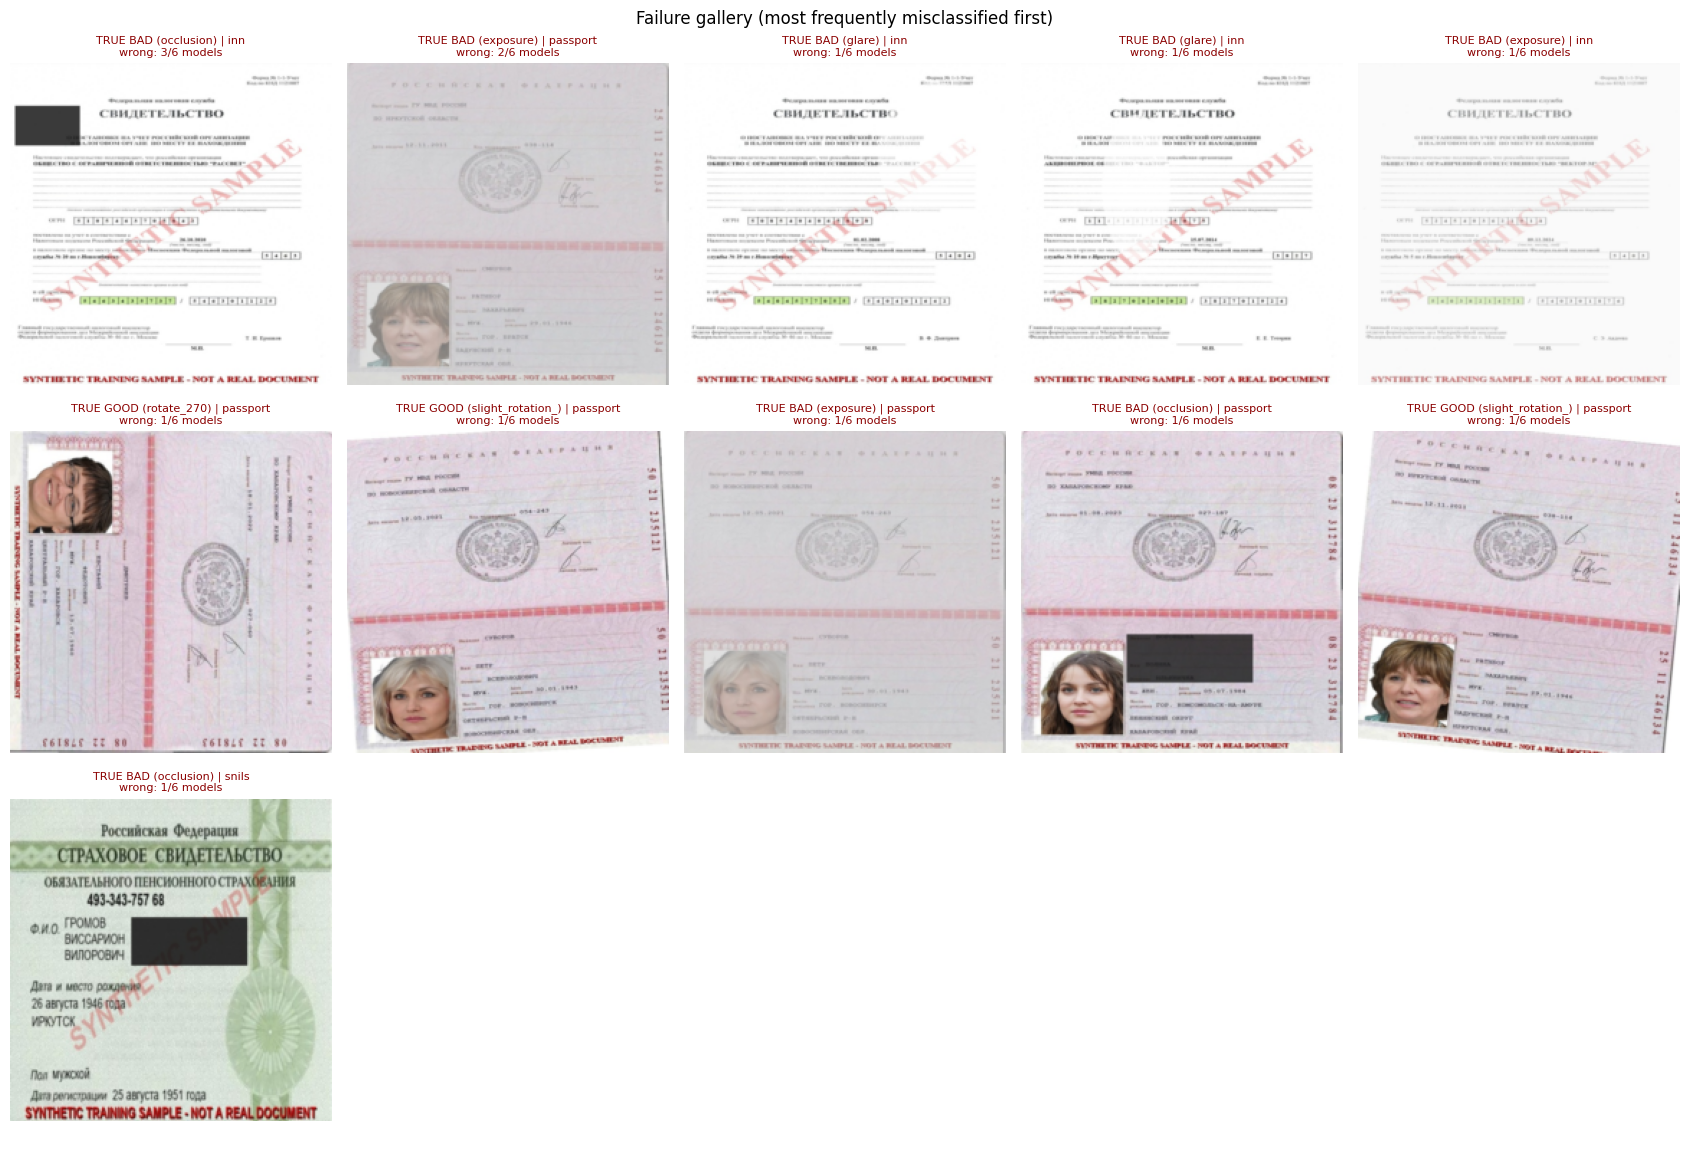

In [10]:
names = list(report)
wrong = np.array([(probs[n] >= .5).astype(int) != y_te.numpy().astype(int) for n in names])   # [models, images]
n_wrong = wrong.sum(axis=0)
idx = [i for i in np.argsort(-n_wrong, kind="stable") if n_wrong[i] > 0]
fail_rows = []
for i in idx:
    r = test_records[i]
    fail_rows.append({"image_id": r["image_id"], "true": r["quality_label"], "class": r["class_name"],
                      "defect/augmentation": r["defect_type"] if r["quality_label"] == "bad" else r["good_augmentation"],
                      "models_wrong": int(n_wrong[i]),
                      "wrong_models": ", ".join(report[n]["display"] for k, n in enumerate(names) if wrong[k, i])})
failures = pd.DataFrame(fail_rows)
failures.to_csv(OUT / "failures.csv", index=False)
print(f"{len(idx)} of {len(test_records)} test images are misclassified by at least one model")
print(failures.groupby(["true", "defect/augmentation"]).size().rename("images").to_string())

show = idx[:15]
cols = 5; rws = int(np.ceil(len(show) / cols))
fig, axes = plt.subplots(rws, cols, figsize=(3.4 * cols, 3.9 * rws))
for ax in np.atleast_1d(axes).flat: ax.axis("off")
for ax, i in zip(np.atleast_1d(axes).flat, show):
    r = test_records[i]
    ax.imshow(x_te[i].permute(1, 2, 0).numpy())
    kind = r["defect_type"] if r["quality_label"] == "bad" else r["good_augmentation"][:16]
    ax.set_title(f"TRUE {r['quality_label'].upper()} ({kind}) | {r['class_name']}\nwrong: {n_wrong[i]}/{len(names)} models",
                 fontsize=8, color="darkred")
plt.suptitle("Failure gallery (most frequently misclassified first)")
plt.tight_layout(); fig.savefig(OUT / "failure_gallery.png", dpi=120); plt.show()

## 8. Save results and the experiment log

In [11]:
(OUT / "comparison_results.json").write_text(json.dumps({
    "hyperparameters": {"frozen": HP_FROZEN, "finetune": HP_FINETUNE},
    "results": report,
    "mean_recall_per_defect": mean_per_defect.round(4).to_dict(),
    "missed_bad_per_defect_all_models": errors_per_defect.to_dict(),
}, indent=2, default=str), encoding="utf-8")

log_path = PRACTICE / "experiment_log.csv"
new = []
for name, hist, hp, best_ep, regime in (("efficientnet_b0", eff_hist, HP_FROZEN, eff_best, "frozen base"),
                                         ("mobilenet_v3_small_ft", ft_hist, HP_FINETUNE, ft_best, "fine-tune last 3 blocks")):
    rep = report[name]
    new.append({"date": time.strftime("%Y-%m-%d %H:%M"), "task": "task4", "model": name, "regime": regime,
                "seed": hp["seed"], "image_size": 224, "batch_size": hp["batch_size"], "optimizer": "Adam",
                "lr": hp["learning_rate"], "epochs_run": len(hist), "best_epoch": best_ep,
                "train_time_s": rep["train_time_s"] if name == "efficientnet_b0" else round(ft_time, 1),
                "test_accuracy": round(rep["metrics"]["accuracy"], 4), "test_precision_bad": round(rep["metrics"]["precision_bad"], 4),
                "test_recall_bad": round(rep["metrics"]["recall_bad"], 4), "test_f1_bad": round(rep["metrics"]["f1_bad"], 4),
                "cpu_latency_ms": rep["cpu_latency_ms"][0], "size_mb": rep["size_mb_fp32"]})
old = pd.read_csv(log_path)
log = pd.concat([old[old["task"] != "task4"], pd.DataFrame(new)], ignore_index=True)
log.to_csv(log_path, index=False)
log

,date,task,model,regime,seed,image_size,batch_size,optimizer,lr,epochs_run,best_epoch,train_time_s,test_accuracy,test_precision_bad,test_recall_bad,test_f1_bad,cpu_latency_ms,size_mb
0,2026-11-02 15:24,task2,mobilenet_v3_small,frozen base,24500003,224,32,Adam,0.0010,30,26,202.9,0.9778,0.9924,0.9630,0.9774,8.9,3.9
1,2026-11-02 15:24,task2,mobilenet_v2,frozen base,24500003,224,32,Adam,0.0010,28,23,983.0,0.9852,0.9852,0.9852,0.9852,17.6,9.3
2,2026-11-08 20:40,task3,yolov8n_cls,full fine-tuning,24500003,224,32,AdamW,0.0010,11,3,346.4,0.9963,1.0000,0.9926,0.9963,10.1,5.6
3,2026-11-08 20:40,task3,yolov8s_cls,full fine-tuning,24500003,224,32,AdamW,0.0010,15,7,1033.5,1.0000,1.0000,1.0000,1.0000,17.7,19.5
4,2026-11-08 20:55,task4,efficientnet_b0,frozen base,24500003,224,32,Adam,0.0010,17,12,626.6,0.9926,1.0000,0.9852,0.9925,31.0,16.2
5,2026-11-08 20:55,task4,mobilenet_v3_small_ft,fine-tune last 3 blocks,24500003,224,32,Adam,0.0001,15,14,148.3,0.9963,1.0000,0.9926,0.9963,10.7,3.9


## 9. Interpretation

**Full comparison (270 test images; all latencies re-measured in this session with the same protocol):**

| Model | Regime | Accuracy | Precision (bad) | Recall (bad) | F1 (bad) | FN / FP | CPU latency | Size | Params | Train time |
|---|---|---|---|---|---|---|---|---|---|---|
| MobileNetV3-Small | frozen | 0.978 | 0.992 | 0.963 | 0.977 | 5 / 1 | 10.4 ms | 3.9 MB | 1.00 M | 3.4 min |
| MobileNetV2 | frozen | 0.985 | 0.985 | 0.985 | 0.985 | 2 / 2 | 20.7 ms | 9.3 MB | 2.39 M | 16.4 min |
| EfficientNet-B0 | frozen | 0.993 | 1.000 | 0.985 | 0.993 | 2 / 0 | 31.0 ms | 16.2 MB | 4.17 M | 10.4 min |
| **YOLOv8n-cls** | full fine-tune | **0.996** | 1.000 | 0.993 | 0.996 | **1 / 0** | **9.5 ms** | 5.6 MB | 1.44 M | 5.8 min |
| YOLOv8s-cls | full fine-tune | **1.000** | 1.000 | 1.000 | 1.000 | 0 / 0 | 18.5 ms | 19.5 MB | 5.08 M | 17.2 min |
| MobileNetV3-Small FT (bonus) | frozen + last 3 blocks | **0.996** | 1.000 | 0.993 | 0.996 | **1 / 0** | 10.7 ms | **3.9 MB** | 1.00 M | 3.4 + 2.5 min |

**Third model (EfficientNet-B0).**
- Among the frozen models it has the best quality: 0.993 accuracy, 0 false alarms. This matches its stronger ImageNet features (77.7 % top-1 vs 67–72 % for the MobileNets).
- It is the **slowest** model: 31 ms with the largest spread (±7 ms). Squeeze-and-excitation blocks and SiLU activations are expensive on CPU, so it gives the worst accuracy-per-millisecond.
- Training curves: no overfitting. Validation loss reaches its minimum at epoch 12, and early stopping ends training at epoch 17.

**Bonus — fine-tuning with a lowered learning rate.**
- Setup: last 3 blocks of MobileNetV3-Small unfrozen, lr 1e-4 (10× lower), 72 % of the weights trainable.
- Result: accuracy **0.978 → 0.996 (+1.85 pp)**, recall(bad) **0.963 → 0.993 (+3.0 pp)**, FN **5 → 1**, FP **1 → 0**, at the same latency and size.
- The curves stay stable: validation loss keeps decreasing to 0.009, with no sign of forgetting thanks to the low learning rate.
- This confirms the Task 3 hypothesis: the gap between YOLO and the Task 2 baseline came mainly from the **training regime** (adapted features vs a frozen head), not from the architecture. With fine-tuning, the 1.0 M-parameter MobileNetV3-Small matches YOLOv8n-cls.

**Error analysis.**
- Only **11 of 270** test images are misclassified by at least one model; 10 of the 11 are wrong for one or two models only.
- **Hardest defect in this dataset: occlusion** (mean recall 0.967, 5 misses over all models), followed by **exposure** (0.976, 4 misses) and **glare** (0.988, 2 misses). Blur and skew are never missed.
- The guide expected glare to be hardest. In our dataset glare is drawn as large ellipses with 60–90 % opacity, which are very visible, except on the **white INN form**, where white-on-white glare almost disappears (both glare misses are INN images).
- **The image missed by 3 models** (`bad_inn_occlusion_289`) has a dark block over the empty top-left corner. It barely covers any text, so it is closer to label noise than to a model error. The two fine-tuned models still detect the block.
- **Exposure errors** are mild low-contrast or over-exposed pages that stay partly readable (passport, INN), again a labelling-strength issue found in the Homework 3 audit.
- **False alarms** (good → bad) only occur for frozen models on rotated passports. All fine-tuned models have 0 false alarms.

**Decision (details in `DECISION_MEMO.md`):** all 6 models pass the Task 1 acceptance criteria. **YOLOv8n-cls** is recommended for the first gate: the fastest model in this session (9.5 ms), recall 0.993 with 0 false alarms, 5.6 MB, and simple training and export. **MobileNetV3-Small FT** is an equal-quality alternative (smallest, permissive licence).
